# Entity resolution, step by step

This notebook runs the pipeline that `scripts/resolve.py` runs on a file of any size: the same `er.run.Run`, one step
per section, on a small generated population (about 3,700 records) so that every step can be seen. It holds no logic
of its own; each section calls the code, then charts what the step did. Every code cell prints its Big-O, filled in
with this file's numbers, and its time. The whole notebook runs in about half a minute.

The run never reads the truth (which records are one entity). It exists only because the data is generated, and the
notebook reads it to show what each step got right.

1 Setup · 2 Generate · 3 Standardize · 4 Person or company · 5 Fit · 6 Rules · 7 Candidates · 8 Score · 9 Why a pair
matches · 10 Threshold · 11 Cluster and evaluate · 12 Increment · 13 How the configuration was chosen · 14 Cost as the
file grows

N records, L characters per value, P pairs inside a key's blocks, C candidate pairs, K comparisons, S sampled pairs.

## 1 · Setup

The chosen pipeline is `config/final.toml`, which `scripts/choose.py` wrote. The demo's population is
`config/generator.toml`'s, made smaller. Charts use one colour per meaning: blue for the same entity (or evidence for
a match), orange for different entities, red for evidence against.

In [1]:
import logging
import math
import shutil
import time
from contextlib import contextmanager
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, PercentFormatter
from matplotlib_inline.backend_inline import set_matplotlib_formats

from er.candidates import found_by
from er.config import column_name, load_pipeline
from er.evaluate import cluster_metrics, missed_pairs, pair_metrics, predicted_pairs
from er.generate import KindProblems, check, generate, kind_problems, load_reference, load_registry, load_spec
from er.io import table_after
from er.kind import SAYS, kind_review_sheet
from er.match import parameters, scaled_prior, waterfall
from er.pipeline import clustered
from er.run import Run, fill_rates
from er.settings import load_settings, shared_name

logging.disable(logging.WARNING)
S = load_settings()
FINAL = load_pipeline(S.root / "config" / "final.toml", S.standardize, S.chains, S.columns)
SPEC = replace(load_spec(S.root / "config" / "generator.toml")[0], entities=3_000)  # the demo's size
DEMO = S.paths["artifacts"] / "demo"
DEMO.mkdir(parents=True, exist_ok=True)
UID, ENT = S.data.unique_id, S.data.entity_id
L, R = f"{UID}_l", f"{UID}_r"
FIELDS = [f for f in S.columns if f not in ("id", "entity")]  # the logical fields of config/settings.toml [columns]
pd.set_option("display.max_columns", 30, "display.width", 200)

BLUE, ORANGE, RED, INK, INK2, MUTED, GRID, AXIS, SURFACE = ("#2a78d6", "#eb6834", "#e34948", "#0b0b0b", "#52514e",
                                                           "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb")
set_matplotlib_formats("svg")
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK2, "axes.titlecolor": INK,
                     "axes.titlesize": 10, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
                     "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED,
                     "xtick.labelcolor": INK2, "ytick.labelcolor": INK2, "font.size": 9, "lines.linewidth": 2,
                     "legend.frameon": False, "figure.dpi": 100})


@contextmanager
def timed(big_o: str):  # a cell's own work, outside the run's steps
    t = time.perf_counter()
    yield
    print(f"{big_o} · {time.perf_counter() - t:.2f}s")


def done(run: Run) -> None:  # the step just run: its Big-O with this file's numbers, and its time
    s = run.steps[-1]
    print(f"{s['step']}: {s['big_o']} = {s['filled']} · {s['seconds']:.2f}s")


def same(pairs: pd.DataFrame) -> np.ndarray:  # the truth, read only to show what a step got right
    return pairs[L].map(entity).to_numpy() == pairs[R].map(entity).to_numpy()


def finish(fig) -> None:
    fig.tight_layout()
    plt.show()

## 2 · Generate

A synthetic population built from public reference data: each entity, a person or a company, is written as one or
more records with typos, empty fields and life changes (a move, a new phone, a married surname). The truth is kept
apart. Below: the entity whose three records differ the most, then how many records each entity has and how often
each column is filled. O(E·r) for E entities of r records each.

generate: O(E·r) = O(3,000 entities · their records) · 0.85s
3,758 records · 3,000 entities · 22% with more than one record


,PHONE_NUM_4,CIF_ID,FULL_NAME_KANA,O_PERSON_NAME_KANA,POST_CD,POST_CD_KANA,LAST_NAME_KANA,GIVEN_NAME_KANA,BIRTH_DATE,SOURCE_ADDR_CD,ORIGINAL_ADDRESS,ADDRESS_FIVE,ADDRESS_FIVE_KANA,ADDR_CD_KANA,ADDR_CD,STD_ADDRESS,ADDRESS_ONE,ADDRESS_TWO,ADDRESS_THREE
CONT_ID,,,,,,,,,,,,,,,,,,,
0000000536,4573,6243089361260,ｸﾎﾞ ｳﾝ,ｸﾎﾞ ｳﾝ,8160831,8160831,ｸﾎﾞ,ｳﾝ,19350813,9035229242,春日市大谷９－１８－９,9-18-9,9-18-9,40218009009,40218009009,福岡県春日市大谷9-18-9,福岡県,春日市,大谷
0000001247,9503,8517481989993,ｸﾎﾞｵﾝ,ｸﾎﾞ ｵﾝ,8000301,8000301,ｸﾎﾞ,ｵﾝ,19360813,8037260253,福岡県京都郡苅田町松原町5-27 グランドール602,5-27,5-27,40621003000,40621003000,福岡県京都郡苅田町松原町5-27,福岡県,京都郡苅田町,松原町
0000001654,4573,5633639874782,クボウン,クボ ウン,8160831,8160831,クボ,ウン,<NA>,9035229242,<NA>,<NA>,<NA>,40218009009,<NA>,<NA>,<NA>,<NA>,<NA>


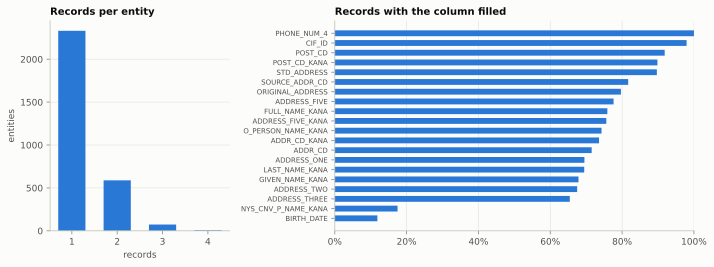

In [2]:
with timed(f"generate: O(E·r) = O({SPEC.entities:,} entities · their records)"):
    g = generate(SPEC, *load_reference(S.paths["reference"]))
    check(SPEC, g)
g.df.to_parquet(DEMO / "records.parquet", index=False)
entity = g.truth.set_index(UID)[ENT]
per_entity = entity.value_counts()
print(f"{len(g.df):,} records · {len(per_entity):,} entities · {(per_entity > 1).mean():.0%} with more than one record")

raw = g.df.set_index(UID)
varied = raw.groupby(entity.reindex(raw.index).to_numpy()).nunique().gt(1).sum(axis=1)  # columns that differ, per entity
example = varied[per_entity.reindex(varied.index).eq(3)].idxmax()
ex_ids = entity.index[entity == example]
display(raw.loc[ex_ids].dropna(axis=1, how="all"))

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.8), width_ratios=[1, 2])
counts = per_entity.value_counts().sort_index()
a.bar(counts.index.astype(str), counts.to_numpy(), width=0.6, color=BLUE)
a.set(title="Records per entity", xlabel="records", ylabel="entities")
a.grid(axis="x", visible=False)
fill = raw.notna().mean().sort_values()
b.barh(fill.index, fill.to_numpy(), height=0.6, color=BLUE)
b.set(title="Records with the column filled", xlim=(0, 1))
b.grid(axis="y", visible=False)
b.xaxis.set_major_formatter(PercentFormatter(1))
b.tick_params(axis="y", labelsize=7)
finish(fig)

## 3 · Standardize

`load` reads the file in chunks and checks it against `config/pipeline.toml` `[fields]`: the id is mandatory, and at
least one of the person and company names is needed. An optional field the file lacks disables only what reads it.
It then builds each logical field from `config/settings.toml` `[columns]` (the first filled source wins) and the
normalizations the pipeline reads: kana folding, legal forms dropped, addresses cut to the street number. Each record
is standardized on its own, so chunks change nothing. O(N·L). Last, the checks `scripts/resolve.py --check` prints:
each field's fill rate, the share of filled values that look like the field (`[locale.detect]`), and the share of
its most common value, where a placeholder such as `0000` would show.

In [3]:
run = Run(FINAL, S)
run.load(DEMO / "records.parquet")
done(run)
print("disabled:", ", ".join(run.disabled) or "nothing: every optional field is in the file")
std = run.con.sql("SELECT * FROM records").df().set_index(UID)

display(std.loc[ex_ids, [f for f in FIELDS if f in std]])  # the entity above, in logical fields (this file has no flag)
rows = []
for field, chain in [("person_name", "fold"), ("company_name", "company"), ("address", "address")]:
    after = column_name(field, S.chains[chain])
    changed = std.loc[std[field].notna() & (std[field] != std[after]), [field, after]].head(3)
    rows.append(changed.set_axis(["before", "after"], axis=1).assign(field=field, normalization=" → ".join(S.chains[chain])))
display(pd.concat(rows)[["field", "normalization", "before", "after"]])
display(fill_rates(run, FIELDS).set_index("field").round(3))

load: O(N·L) = O(3,758·L) · 0.11s
disabled: nothing: every optional field is in the file


,full_name,person_name,given_name,company_name,any_name,address,address_code,postal_code,prefecture,town_code,city,phone,customer_id,birth_date
CONT_ID,,,,,,,,,,,,,,
0000000536,クボウン,クボウン,ウン,NaN,クホウン,福岡県春日市大谷9-18-9,9035229242,8160831,福岡県,40218009009,春日市,4573,6243089361260,19350813
0000001247,クボオン,クボオン,オン,NaN,クホオン,福岡県京都郡苅田町松原町5-27,8037260253,8000301,福岡県,40621003000,京都郡苅田町,9503,8517481989993,19360813
0000001654,クボウン,クボウン,ウン,NaN,クホウン,NaN,9035229242,8160831,NaN,NaN,NaN,4573,5633639874782,NaN


,field,normalization,before,after
CONT_ID,,,,
0000000005,person_name,kana_fold,タジツコーダイ,タシツコウタイ
0000000006,person_name,kana_fold,マツザキトモアギ,マツサキトモアキ
0000000008,person_name,kana_fold,ヨネクラギョーシン,ヨネクラキヨウシン
0000000007,company_name,nfkc → strip_legal_form → kana_fold,イスズエンジンセイゾウホッカイドウカブシキガイシャ,イススエンシンセイソウホツカイトウ
0000000013,company_name,nfkc → strip_legal_form → kana_fold,カブシキガイシャグラニツト,クラニツト
0000000017,company_name,nfkc → strip_legal_form → kana_fold,ナルミヤインターナショナル,ナルミヤインタウナシヨナル
0000000002,address,address,神奈川県海老名市門沢橋2-23-5,海老名市門沢橋2-23-5
0000000003,address,address,福島県福島市北町5-30,福島市北町5-30
0000000004,address,address,佐賀県佐賀市12-26,佐賀市12-26


,filled,looks_right,top_value,flag
field,,,,
full_name,0.759,1.000,0.001,
person_name,0.779,1.000,0.001,
given_name,0.679,1.000,0.004,
company_name,0.175,0.798,0.003,
any_name,0.954,1.000,0.001,
address,0.936,0.788,0.003,
address_code,0.817,1.000,0.002,
postal_code,0.928,1.000,0.002,
prefecture,0.695,1.000,0.115,


## 4 · Person or company

Each record gets a kind, `er.kind`: 2 company, 1 person, 0 not sure, the codes a person/company flag uses. A legal form
written where banks write one (株式会社 in full, カ)〇〇, 〇〇(カ) says company. A name model, logistic regression on the
name's character n-grams trained once on public data (real company readings from the registry, and the personas), says
where a name leans. With people's answers, a combiner weighs the name's score, the file's own flag, the birth year and
the legal form, and a line on each side keeps the sure calls within budget: at most 0.1% of company calls wrong, 1% of
person calls. A record where the engine and the flag disagree is held back from matching until a person decides: its
name goes to neither side, so it can't be merged with the wrong kind.

Here the population of section 2 gets one name column for every kind, NAME_KANA, and what makes the kinds hard to tell
apart (`er.generate.kind_problems`): real company names written as banks write them, company records under their
representative's name, sole traders named like a shop, companies with a date in the birth-date column, and a flag that
is sometimes wrong. It is loaded twice: without answers, then with people's answers to its review sheet (here, the
truth). Below: the review sheet, which says in words why each record is on it; what the answers let the engine decide;
and how the name alone scores each kind of record. O(N·L) per load.

load: O(N·L) = O(3,758·L) · 0.10s
review sheet: 150 records to decide, 600 drawn to measure


,why,reason,engine_says,name_says,flag,name
0,decide,"the engine is sure it is 2 company, the flag says 1: held back from matching until you decide",2 company,2 company (100.0%),1,ティーアンドピーサクセスマップジャパン(カ
1,decide,"the engine is sure it is 2 company, the flag says 1: held back from matching until you decide",2 company,2 company (100.0%),1,カ)ネイチャー
2,decide,"the engine is sure it is 2 company, the flag says 1: held back from matching until you decide",2 company,2 company (100.0%),1,カ)アールアンドシークリエイティブグループ
150,measure,"drawn at random, to measure the flag and the engine",0 not sure,1 person (99.2%),1,ハマャ ギエコ
151,measure,"drawn at random, to measure the flag and the engine",0 not sure,1 person (100.0%),1,ヨシタケ ヒロオ
152,measure,"drawn at random, to measure the flag and the engine",0 not sure,1 person (98.5%),1,フルャケンイチ


load: O(N·L) = O(3,758·L) · 0.77s
750 answers, 600 of them drawn to measure: company at P ≥ 0.995, person never (no line holds its budget); the flag wrong on 4.5% of the answers drawn at random
held back from matching, the engine and the flag disagreeing: 24 records


the engine says,0 not sure,1 person,2 company
the record is,,,
company,261,0,493
person,2265,534,0
representative,19,0,12
sole trader,86,88,0


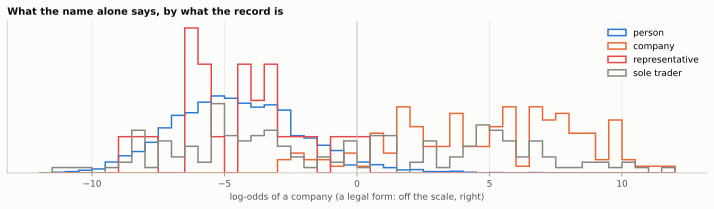

In [4]:
kg = kind_problems(g, KindProblems(), load_registry(S.paths["reference"]), S.standardize.legal_front, S.standardize.legal_end,
                   SPEC.kana_confusions, SPEC.branches)
kg.df.to_parquet(DEMO / "kinds.parquet", index=False)
KS = shared_name(S, "NAME_KANA")  # every name field reads NAME_KANA: full_name and person_name where a record leans person, company_name where it leans company
KFINAL = load_pipeline(S.root / "config" / "final.toml", KS.standardize, KS.chains, KS.columns)
case = kg.truth.set_index(UID)["CASE"]
kinds_of = lambda r: r.con.sql(f'SELECT "{UID}", kind_name AS name, kind_flag, birth_date, kind, kind_p, kind_by, name_p, kind_held FROM records').df()

free = Run(KFINAL, KS)
free.load(DEMO / "kinds.parquet")
done(free)
sheet = kind_review_sheet(free.con, "records", UID, replace(KFINAL.kind, labels_to_draw=600, review_max=150), KS.flag_company)
print(f"review sheet: {(sheet['why'] == 'decide').sum():,} records to decide, {(sheet['why'] == 'measure').sum():,} drawn to measure")
with pd.option_context("display.max_colwidth", 110):  # each row's reason, whole
    display(sheet.groupby("why").head(3)[["why", "reason", "engine_says", "name_says", "flag", "name"]])

sheet["kind"] = np.where(kg.truth.set_index(UID).loc[sheet[UID], "KIND"].eq("company"), 2, 1)  # people's answers: here, the truth
sheet.to_parquet(DEMO / "kind_answers.parquet")
answered = Run(KFINAL, KS, kind_labels=DEMO / "kind_answers.parquet")
answered.load(DEMO / "kinds.parquet")
done(answered)
c = answered.classifier
line = lambda x, at: at if x <= 1 else "never (no line holds its budget)"
print(f"{c.labels:,} answers, {c.measured:,} of them drawn to measure: company {line(c.line_company, f'at P ≥ {c.line_company:g}')}, "
      f"person {line(c.line_person, f'at P ≤ {1 - c.line_person:.3g}')}; the flag wrong on {c.flag_error:.1%} of the answers drawn at random")
after = kinds_of(answered).set_index(UID).join(case.rename("case"))
print(f"held back from matching, the engine and the flag disagreeing: {int(after['kind_held'].sum()):,} records")
display(pd.crosstab(after["case"], after["kind"].map(SAYS)).rename_axis(index="the record is", columns="the engine says"))

fig, ax = plt.subplots(figsize=(10, 3))
bins = np.linspace(-12, 12, 49)
logodds = np.log(after["name_p"].clip(1e-6, 1 - 1e-6) / (1 - after["name_p"].clip(1e-6, 1 - 1e-6)))
for who, color in (("person", BLUE), ("company", ORANGE), ("representative", RED), ("sole trader", MUTED)):
    ax.hist(logodds[after["case"] == who], bins=bins, histtype="step", linewidth=1.5, color=color, label=who, density=True)
ax.axvline(0, color=AXIS, linewidth=0.8)
ax.set(title="What the name alone says, by what the record is", xlabel="log-odds of a company (a legal form: off the scale, right)", yticks=[])
ax.legend()
finish(fig)

## 5 · Fit, without labels

Fellegi–Sunter weighs each comparison's agreement level by how much likelier it is for a true match than by chance:
log2(m/u) bits. With no labels, λ (the chance two random records match) comes from near-certain rules and their
measured recall; u (agreement by chance) from value counts for each comparison's leading exact levels and a random sample
of pairs for the rest; m (agreement for true matches) by EM on blocks of equal phones or addresses. The fit uses a fixed-size sample of
whole postal areas, so its cost doesn't grow with the file. Then u is measured again on the whole file: how often two
records agree by chance depends on how many records there are, and u from the sample would understate the evidence
of an agreement on the file. The gate on oversized blocks (section 7) and the scores (section 8) both use these.
Below: the bits each level is worth on this file. O(n + S·K + P_em·K) + O(N + S·K).

fit: O(n + S·K + P_em·K) + O(N + S·K) = n = 3,758; u on 3,758 records · 5.68s
λ = 1.47e-04 at 3,758 records: a pair starts at -12.7 bits


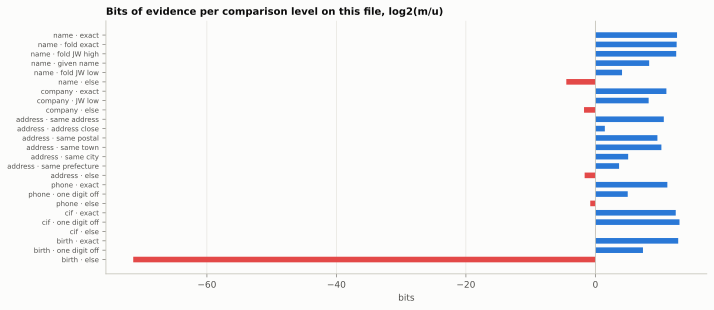

In [5]:
model = run.fit()
done(run)
lam = scaled_prior(model, run.n)
print(f"λ = {lam:.2e} at {run.n:,} records: a pair starts at {math.log2(lam / (1 - lam)):.1f} bits")
params = parameters(run.scoring).dropna(subset=["weight"]).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 4.4))
ax.barh(params["comparison"] + " · " + params["level"], params["weight"], height=0.6,
        color=np.where(params["weight"] >= 0, BLUE, RED))
ax.axvline(0, color=AXIS, linewidth=0.8)
ax.set(title="Bits of evidence per comparison level on this file, log2(m/u)", xlabel="bits")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", labelsize=7)
finish(fig)

## 6 · Rules

Stage 1 is deterministic. An exact rule joins records equal on all its keys; a fuzzy rule needs some keys equal and
others close (names within two edits, company names by shared characters, addresses by Jaro–Winkler, a phone one
digit off). Before any join, `budget` counts every rule's pairs
P = Σ C(k, 2) over its key blocks and stops the run if one is over budget. The first rule in order wins a pair, and a
fuzzy pair is kept only if it touches a record the exact rules left alone. Left: how many true pairs the rules join,
clusters included. Right: the true pairs each rule joins itself.

budget: O(N) = O(3,758) per rule and generator · 0.06s


rules: O(N + Σ P_r·L²) + O(E·d + N) = O(3,758 + 91 pairs) · 0.05s


,P,largest_block,joined,true
rule,,,,
X1_CIF_PERSON_NAME,2,2,2,2
X2_CIF_COMPANY_NAME,0,1,0,0
X3_CIF_PHONE,3,2,2,2
X4_PERSON_NAME_ADDRCD_PHONE,23,2,22,22
X5_COMPANY_NAME_ADDRCD_PHONE,0,1,0,0
F1_NAME~_ADDRCD_PHONE,89,2,44,44
F2_NAME~_ADDRESS~_PHONE,83,3,5,5
F3_NAME~_CIF,14,2,6,6
F4_NAME_ADDRCD_PHONE~,58,3,3,3


the rules join 10.9% of the 855 true pairs, with 0 false


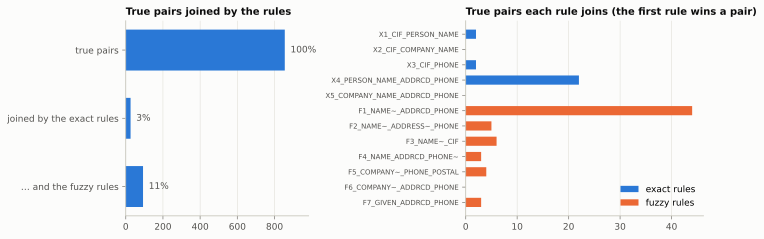

In [6]:
plan = run.budget()
done(run)
run.rules()
done(run)
kept = run.con.sql("SELECT * FROM rule_kept").df().assign(true=same)
order = [r.name for st in FINAL.rules.stages for r in st.rules]
stage_of = {r.name: st.name for st in FINAL.rules.stages for r in st.rules}
per_rule = (plan[plan["kind"] == "rule"].set_index("name")[["est_pairs", "largest_block"]].rename(columns={"est_pairs": "P"})
            .join(kept.groupby("rule")["true"].agg(joined="size", true="sum")).fillna(0).astype(int).reindex(order))
display(per_rule.rename_axis("rule"))

rule_clusters = run.con.sql("SELECT * FROM rule_clusters").df().set_index(UID)["cluster_id"]
exact_only = clustered(run.con, run.db, pd.DataFrame({UID: std.index, "cluster_id": std.index}), kept[kept["stage"] == "exact"],
                       pd.Series(std.index), UID)  # the run's own clustering, on the exact rules' pairs alone
m_exact, m_rules = (pair_metrics(c, entity.reindex(c.index)) for c in (exact_only, rule_clusters))
total = m_rules["TP"] + m_rules["FN"]
print(f"the rules join {m_rules['recall']:.1%} of the {total:,} true pairs, with {m_rules['FP']} false")

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.4), width_ratios=[1, 1.3])
funnel = pd.Series({"true pairs": total, "joined by the exact rules": m_exact["TP"], "… and the fuzzy rules": m_rules["TP"]})[::-1]
a.barh(funnel.index, funnel.to_numpy(), height=0.6, color=BLUE)
for y, v in enumerate(funnel.to_numpy()):
    a.text(v, y, f"  {v / total:.0%}", va="center", color=INK2)
a.set(title="True pairs joined by the rules", xlim=(0, total * 1.15))
a.grid(axis="y", visible=False)
y = np.arange(len(order))[::-1]
for stage, colour in (("exact", BLUE), ("fuzzy", ORANGE)):
    mask = np.array([stage_of[r] == stage for r in order])
    b.barh(y[mask], per_rule["true"].to_numpy()[mask], height=0.6, color=colour, label=f"{stage} rules")
b.set_yticks(y, order, fontsize=7)
b.set(title="True pairs each rule joins (the first rule wins a pair)")
b.grid(axis="y", visible=False)
b.legend(loc="lower right")
finish(fig)

## 7 · Candidates

Stage 2 compares only pairs that some generator lists. A key generator pairs records equal on all its keys; a
deletion-key generator pairs names one edit apart (each value and its one-character deletions, within a postal
area); a sorted window pairs neighbours in sorted order. Each is one SQL join or window over the records table; their
pairs are merged, and pairs inside one rule cluster are dropped. Every key here pairs a share of the records that stays
flat as the file grows: a field with a fixed pool of values (the phone's last digits, an address shared by a household)
is always combined with another. O(N·L + Σ P_g).

candidates: O(N·L + Σ P_g) = O(3,758·L + 20,977) · 0.15s


,generator,big_o,pairs,finds,different_entity_pairs,seconds
0,cif,O(N + P),4,0.005,0,0.004
1,sn_company_name,O(N log N + N·w),1961,0.100,1885,0.003
2,phone_prefecture,O(N + P),131,0.152,15,0.004
3,phone_postal_area,O(N + P),58,0.073,2,0.004
4,phone_name_initial,O(N + P),177,0.198,26,0.004
5,sn_person_name,O(N log N + N·w),8679,0.589,8230,0.004
6,sn_person_name_reversed,O(N log N + N·w),8664,0.652,8167,0.004
7,person_name,O(N + P),414,0.521,17,0.005
8,company_name,O(N + P),61,0.072,6,0.004
9,company_name_deletions,O(N·L + P),77,0.079,17,0.005


18,994 candidate pairs · together they list 87.3% of the 762 true pairs the rules left apart


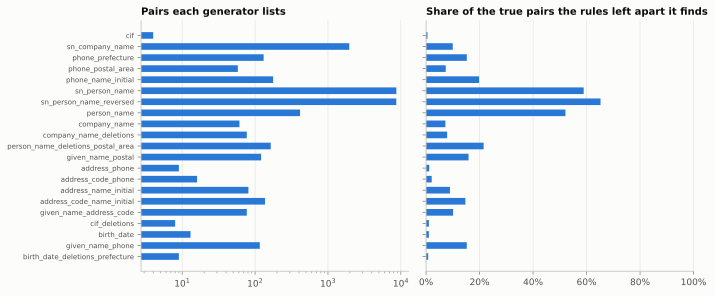

In [7]:
report = run.candidates()
done(run)
cands = run.con.sql("SELECT * FROM cands").df().assign(true=same)
targets = missed_pairs(rule_clusters, entity.reindex(rule_clusters.index), UID)  # true pairs the rules left apart
wanted = set(zip(targets[L].astype(str), targets[R].astype(str)))
on_target = np.array([k in wanted for k in zip(cands[L], cands[R])])
report["finds"] = [(found_by(cands, {name}) & on_target).sum() / len(wanted) for name in report["generator"]]
report["different_entity_pairs"] = [(found_by(cands, {name}) & ~cands["true"]).sum() for name in report["generator"]]
display(report[["generator", "big_o", "pairs", "finds", "different_entity_pairs", "seconds"]].round(3))
print(f"{len(cands):,} candidate pairs · together they list {on_target.sum() / len(wanted):.1%} of the {len(wanted):,} true pairs the rules left apart")

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
y = np.arange(len(report))[::-1]
a.barh(y, report["pairs"], height=0.6, color=BLUE)
a.set(title="Pairs each generator lists", xscale="log")
b.barh(y, report["finds"], height=0.6, color=BLUE)
b.set(title="Share of the true pairs the rules left apart it finds", xlim=(0, 1))
b.xaxis.set_major_formatter(PercentFormatter(1))
a.set_yticks(y, report["generator"], fontsize=7)
for ax in (a, b):
    ax.grid(axis="y", visible=False)
finish(fig)

## 8 · Score

Every candidate pair gets its weight: the prior plus each comparison's bits, with the u section 5 measured on this
file. A pair is accepted at the threshold `scripts/choose.py` chose. O(C·K·L²).

score: O(C·K·L²) = O(18,994·6·L²) · 0.12s
18,994 pairs scored · 308 reach 8 bits, 308 of them true


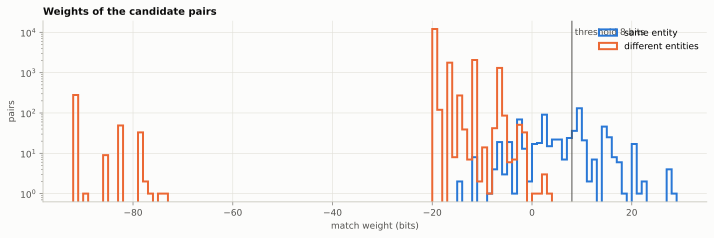

In [8]:
run.score()
done(run)
scores = run.con.sql("SELECT * FROM scores").df().assign(same=same)
threshold = run.pipeline.fs.min_match_weight
w = scores["match_weight"]
print(f"{len(scores):,} pairs scored · {(w >= threshold).sum():,} reach {threshold:g} bits, "
      f"{(scores['same'] & (w >= threshold)).sum():,} of them true")

fig, ax = plt.subplots(figsize=(10, 3.4))
bins = np.arange(math.floor(w.min()), math.ceil(w.max()) + 1)
ax.hist(w[scores["same"]], bins, histtype="step", color=BLUE, linewidth=2, label="same entity")
ax.hist(w[~scores["same"]], bins, histtype="step", color=ORANGE, linewidth=2, label="different entities")
ax.axvline(threshold, color=INK2, linewidth=1)
ax.text(threshold, ax.get_ylim()[1], f" threshold {threshold:g} bits", va="top", color=INK2)
ax.set(title="Weights of the candidate pairs", xlabel="match weight (bits)", ylabel="pairs", yscale="log")
ax.legend(loc="upper right")
finish(fig)

## 9 · Why a pair matches

A weight is a sum, so it can be read term by term. Two pairs: the accepted true match closest to the threshold whose
names differ, and the rejected pair of different entities closest to it. Each bar is one term: the prior, then the
bits of the level each comparison landed in.

,full_name,company_name,address,phone,customer_id
CONT_ID,,,,,
0000000399,ヤベケイト,NaN,東京都昭島市田中町2-12-24,4505,8766633794722
0000001035,ャベケイド,NaN,東京都港区西新橋1-20-5,4501,1909916302348


,full_name,company_name,address,phone,customer_id
CONT_ID,,,,,
0000001923,サンガジシリナオキ,NaN,茨城県常総市水海道天満町10-8,4162,1305064375017
0000002186,NaN,アサヒアルミサンギョウカブシキガイシャオオサカシテン,茨城県常総市21-14,4162,8324699326995


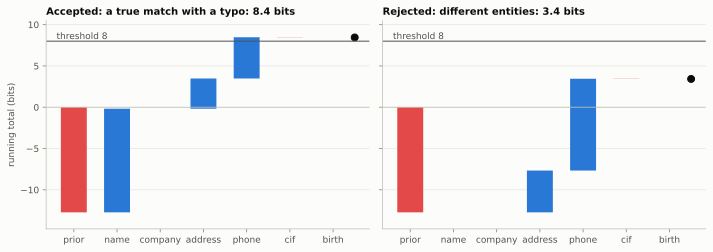

In [9]:
show = list(FINAL.explain_show)
filled = list(FINAL.explain_filled)
left, right = std.loc[scores[L], show].set_index(scores.index), std.loc[scores[R], show].set_index(scores.index)
both_filled = (left[filled].notna() & right[filled].notna()).all(axis=1)
differs = (left[filled[0]] != right[filled[0]]).fillna(False)
accepted = w >= threshold
picked = {"Accepted: a true match with a typo": scores[accepted & scores["same"] & both_filled & differs].sort_values(["match_weight", L, R]).head(1),
          "Rejected: different entities": scores[~accepted & ~scores["same"]].sort_values(["match_weight", L, R], ascending=[False, True, True]).head(1)}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
ends = []
for ax, (title, pair) in zip(axes, picked.items()):
    row = pair.iloc[0]
    display(std.loc[[row[L], row[R]], show])
    bits = waterfall(run.scoring, {c.name: row[f"gamma_{c.name}"] for c in run.pipeline.fs.model.comparisons}, run.n)
    end = bits["bits"].cumsum().to_numpy()
    start = np.concatenate([[0], end[:-1]])
    ends += [*start, *end]
    ax.bar(bits["evidence"], bits["bits"], bottom=start, width=0.6, color=np.where(bits["bits"] >= 0, BLUE, RED))
    ax.plot(len(bits) - 0.5, end[-1], marker="o", markersize=7, color=INK, clip_on=False)
    ax.axhline(threshold, color=INK2, linewidth=1)
    ax.text(-0.4, threshold, f"threshold {threshold:g}", va="bottom", color=INK2)
    ax.axhline(0, color=AXIS, linewidth=0.8)
    ax.set(title=f"{title}: {row['match_weight']:.1f} bits")
    ax.grid(axis="x", visible=False)
axes[0].set(ylabel="running total (bits)", ylim=(min(ends) - 2, max(ends + [threshold]) + 2))
finish(fig)

## 10 · Threshold

`scripts/choose.py` chose the threshold on cross-validated labelled data: the lowest weight at which no false pair
was accepted and the upper bound of the false-merge rate stays under 5%, then one step stricter. A run without labels
uses it as it is. Here, with this file's truth: what each weight would accept.

O(C·G) = O(18,994 pairs · 25 weights) · 0.00s


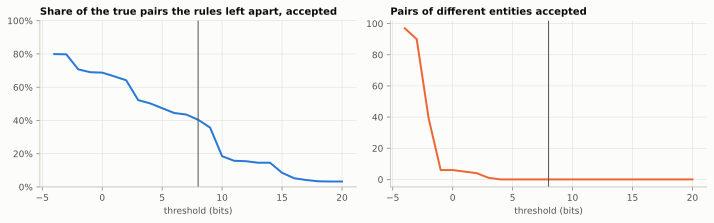

In [10]:
with timed(f"O(C·G) = O({len(scores):,} pairs · 25 weights)"):
    grid = np.arange(-4.0, 21.0)
    curve = pd.DataFrame({"weight": grid,
                          "recall": [(scores["same"] & (w >= x)).sum() / len(wanted) for x in grid],
                          "false_pairs": [(~scores["same"] & (w >= x)).sum() for x in grid]})

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.2))
a.plot(curve["weight"], curve["recall"], color=BLUE)
a.set(title="Share of the true pairs the rules left apart, accepted", xlabel="threshold (bits)", ylim=(0, 1))
a.yaxis.set_major_formatter(PercentFormatter(1))
b.plot(curve["weight"], curve["false_pairs"], color=ORANGE)
b.set(title="Pairs of different entities accepted", xlabel="threshold (bits)")
for ax in (a, b):
    ax.axvline(threshold, color=INK2, linewidth=1)
finish(fig)

## 11 · Cluster and evaluate

The accepted pairs and the rules' pairs are clustered together (connected components, in SQL). Gold gives each
record its cluster and what resolved it: a rule, or the model. Without labels, the run also says how many of the model's links it
expects to be false: the sum of 1 − match probability over them. Then, with the truth: pairwise recall with its 95%
interval, false merges, and the upper bound of the false-merge rate. Below: cluster sizes against true entity sizes,
and the largest cluster. Each customer's kind comes from its records: 2 company if any record surely is one, 1 person if
no record leans company and one surely is a person, else 0 not sure. This file has no flag and nobody answered, so only a
written legal form makes a company (section 4 shows the rest). O(C + E·d + N).

cluster: O(C + E·d + N) = O(18,994 + 300·d + 3,758) · 0.03s
write: O(N + C) = O(3,758 + 300) · 0.02s
model links 300 · false as the model expects 0.28 · false with the truth 0
recall 48.0% (44.6%–51.3%) · false merges 0 (rate at most 0.73%) · precision 100.00%


,records
resolved by,
(alone),3067
fs,511
F1_NAME~_ADDRCD_PHONE,88
X4_PERSON_NAME_ADDRCD_PHONE,44
F3_NAME~_CIF,11
F2_NAME~_ADDRESS~_PHONE,9
F5_COMPANY~_PHONE_POSTAL,8
F7_GIVEN_ADDRCD_PHONE,6
F4_NAME_ADDRCD_PHONE~,6


customers: 2,882 × 0 not sure · 511 × 2 company


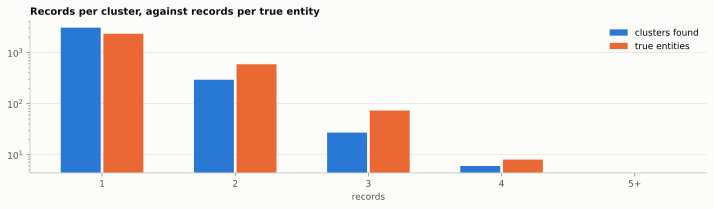

,full_name,company_name,address,phone,customer_id,entity
CONT_ID,,,,,,
0000000640,コバヤシタツヤ,NaN,埼玉県ふじみ野市上ノ原1-3-21,7543,8480021922415,E001400
0000000998,コバヤシタツヤ,NaN,埼玉県ふじみ野市上ノ原1-3-21,7543,3057483762514,E001400
0000001974,コバヤシタツヤ,NaN,埼玉県ふじみ野市上ノ原1-3-21,4477,8334742939420,E001400
0000002491,コバヤシタツヤ,NaN,埼玉県さいたま市浦和区駒場2-25-10,7543,1663636056484,E001400


In [11]:
run.cluster()
done(run)
shutil.rmtree(DEMO / "run", ignore_errors=True)
run.write(DEMO / "run")
done(run)
gold = pd.read_parquet(DEMO / "run" / "gold.parquet").set_index(UID)
m = cluster_metrics(gold["cluster_id"], entity.reindex(gold.index))
linked = next(s for s in run.steps if s["step"] == "cluster")
print(f"model links {linked['accepted']:,} · false as the model expects {linked['expected_false']:.2f} · "
      f"false with the truth {(~same(run.con.sql('SELECT * FROM matches').df())).sum()}")
print(f"recall {m['recall']:.1%} ({m['recall_lo']:.1%}–{m['recall_hi']:.1%}) · false merges {m['FP']} "
      f"(rate at most {m['fp_rate_hi']:.2%}) · precision {m['precision']:.2%}")
display(gold["resolved_by"].fillna("(alone)").value_counts().rename_axis("resolved by").to_frame("records"))
print("customers:", " · ".join(f"{n:,} × {SAYS[k]}" for k, n in gold.drop_duplicates("cluster_id")["customer_kind"].value_counts().items()))

sizes = lambda ids: ids.value_counts().clip(upper=5).value_counts().reindex(range(1, 6), fill_value=0)
fig, ax = plt.subplots(figsize=(10, 3))
x = np.arange(1, 6)
ax.bar(x - 0.16, sizes(gold["cluster_id"]), width=0.3, color=BLUE, label="clusters found")
ax.bar(x + 0.16, sizes(entity), width=0.3, color=ORANGE, label="true entities")
ax.set_xticks(x, ["1", "2", "3", "4", "5+"])
ax.set(title="Records per cluster, against records per true entity", xlabel="records", yscale="log")
ax.grid(axis="x", visible=False)
ax.legend()
finish(fig)
largest = gold["cluster_id"].value_counts().index[0]
display(std.loc[gold.index[gold["cluster_id"] == largest], show].assign(entity=entity))

## 12 · Increment

New records only. An increment joins the batch against all the records, rule by rule and generator by generator,
scores the pairs that touch it, and merges into the stored clusters, each existing cluster one node. So its cost grows
with the batch, not with the file. Here: a full run on 90% of the records with the model fitted above, then the other
10% as an increment, compared with the full run on all of them in section 11. The increment keeps the stored u, except
the exact levels, which it counts again: a comparison's sampled u are measured again only once the drift of its exact
level exceeds their sampling error, since a new sample would otherwise only redraw the noise. The steps that follow
the data (rules, candidates, cluster) follow the batch.

increment load: O(N·L) = O(390·L) · 0.05s
increment fit: O(N + S·K_stale) = O(3,758 + 10,000,000·2) · 4.12s
increment rules: O(|Δ|·Σ b + scan) = O(390 new records) · 0.05s
increment candidates: O(|Δ|·Σ b + scan) = 3,814 pairs touching the batch · 0.11s
increment score: O(C_Δ·K·L²) = O(3,814·6·L²) · 0.08s
increment cluster: O(C_Δ + touched clusters) = 61 accepted · 0.03s
increment write: O(N + C) = O(3,758 + 61) · 0.01s
u of name: drifted 0.063 bits, sampling error 0.017 → sampled again
u of company: drifted 0.072 bits, sampling error 0.126 → kept
u of address: drifted 0.012 bits, sampling error 0.004 → sampled again
u of phone: drifted 0.017 bits, sampling error inf → kept
u of cif: drifted 0.170 bits, sampling error inf → kept
u of birth: drifted 0.336 bits, sampling error inf → kept
390 new records · 73 joined an existing cluster · pairs only in the increment: 6 true, 0 false · only in the full run: 0 true, 0 false


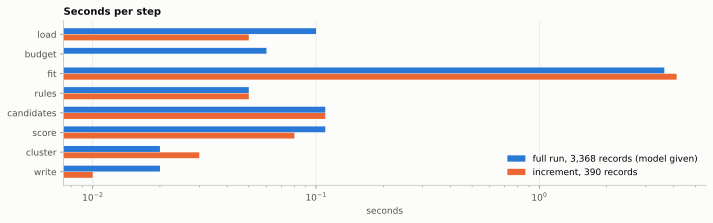

In [12]:
batch = np.random.default_rng(0).random(len(g.df)) < 0.1
g.df[~batch].to_parquet(DEMO / "first_90.parquet", index=False)
g.df[batch].to_parquet(DEMO / "new_10.parquet", index=False)
shutil.rmtree(DEMO / "increment", ignore_errors=True)
base = Run(FINAL, S, model=model).full(DEMO / "first_90.parquet", DEMO / "increment")
inc = Run(FINAL, S).increment(DEMO / "new_10.parquet", DEMO / "increment")
for s in inc.steps:
    print(f"increment {s['step']}: {s['big_o']} = {s['filled']} · {s['seconds']:.2f}s")
for name, b in inc.basis.items():  # what the increment did with u, comparison by comparison
    x = b["last_check"]
    se = x["se_bits"] if x["se_bits"] is not None else float("inf")
    print(f"u of {name}: drifted {x['drift_bits']:.3f} bits, sampling error {se:.3f} → {'sampled again' if x['drift_bits'] > se else 'kept'}")

after = pd.read_parquet(DEMO / "increment" / "gold.parquet").set_index(UID)["cluster_id"]
new_ids = set(g.df.loc[batch, UID])
old_in = after[~after.index.isin(new_ids)].unique()
joined = after[after.index.isin(new_ids) & after.isin(old_in)]
truth = predicted_pairs(entity)
by_inc, by_full = predicted_pairs(after), predicted_pairs(gold["cluster_id"])
print(f"{batch.sum():,} new records · {len(joined):,} joined an existing cluster · pairs only in the increment: "
      f"{len((by_inc - by_full) & truth)} true, {len((by_inc - by_full) - truth)} false · only in the full run: "
      f"{len((by_full - by_inc) & truth)} true, {len((by_full - by_inc) - truth)} false")

steps = ["load", "budget", "fit", "rules", "candidates", "score", "cluster", "write"]
seconds = lambda r: pd.Series({s["step"]: s["seconds"] for s in r.steps}).reindex(steps, fill_value=0)
fig, ax = plt.subplots(figsize=(10, 3.2))
y = np.arange(len(steps))[::-1]
ax.barh(y + 0.16, seconds(base), height=0.3, color=BLUE, label=f"full run, {(~batch).sum():,} records (model given)")
ax.barh(y - 0.16, seconds(inc), height=0.3, color=ORANGE, label=f"increment, {batch.sum():,} records")
ax.set_yticks(y, steps)
ax.set(title="Seconds per step", xlabel="seconds", xscale="log")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
finish(fig)

## 13 · How the configuration was chosen

`scripts/choose.py` starts from `config/pipeline.toml` and tries the changes in `config/experiments.py` in order, each
on top of the choice so far, on labelled synthetic data. A change is adopted by the decision rule: "better" needs a
significant paired gain on the selection set; "cheaper" and "safer", no true pair lost; "chosen" is the owner's call,
where no false pair may be added. On validation, all but "chosen" must lose no true pair. Test is scored once, at the end. Its tables are in
`reports/choose.md`; read here, not recomputed.

In [13]:
text = (S.root / "reports" / "choose.md").read_text(encoding="utf-8")
for stage in ("## Stage 1: rules", "## Stage 2: Fellegi–Sunter"):
    decisions = table_after(text.split(stage, 1)[1], "### Decisions")
    print(stage[3:])
    display(decisions.iloc[:, :8])
print(next(line for line in (S.root / "config" / "final.toml").read_text(encoding="utf-8").splitlines() if line.startswith("# Adopted")))

Stage 1: rules


,change,kind,adopted,train_TP_gains,train_TP_losses,train_p,train_FP_added,train_FP_removed
0,fold_levenshtein,better,True,17,4,0.0072,0,0
1,fold_exact,cheaper,False,0,83,0.0,0,0
2,f2_address_exact,cheaper,True,0,0,1.0,0,0
3,f2_address_prefix,cheaper,True,0,0,1.0,0,0
4,optuna_comparators,better,True,33,0,0.0,0,0


Stage 2: Fellegi–Sunter


,change,kind,adopted,cv_TP_gains,cv_TP_losses,cv_p,cv_FP_added,cv_FP_removed
0,no_term_frequency,better,True,12,0,0.0005,0,0
1,exact_keys_only,cheaper,True,0,0,1.0,0,0
2,optuna_suggestion,better,True,1488,1,0.0,0,0
3,u_from_1e6_pairs,cheaper,False,1,8,0.0391,0,0
4,compound_phone_keys,cheaper,True,0,0,1.0,0,0
5,sorted_names_for_tfidf,cheaper,True,1,0,1.0,0,0
6,name_keys,safer,True,1,0,1.0,0,0
7,bounded_address_keys,cheaper,True,0,0,1.0,0,0
8,no_sorted_windows,cheaper,False,0,0,1.0,0,0
9,bridge_rule_clusters,better,False,0,0,1.0,0,0


# Adopted: rules fold_levenshtein, f2_address_exact, f2_address_prefix, optuna_comparators; Fellegi–Sunter no_term_frequency, exact_keys_only, optuna_suggestion, compound_phone_keys, sorted_names_for_tfidf, name_keys, bounded_address_keys, u_from_scored_file, u_exact_by_counts, cif_one_digit_off, cif_deletion_key, graded_address, birth_date, birth_date_key, given_name_phone_key, birth_date_deletion_key, u_near_by_keys, fit_u_from_1e6_pairs, company_without_jw_high, name_needed.


## 14 · Cost as the file grows

Every step's Big-O, for this full run and for the increment, with the numbers filled in. A full run is
O(N·L + Σ P + C·K·L² + E·d), plus the fit and the u sample, whose sizes are fixed. When every key's pairs
per record stay flat, that is linear in N. An increment of Δ records costs O(|Δ|·(L + Σ b) + C_Δ·K·L²) plus scans of
the stored records. Below, measured by `scripts/benchmark.py` (`reports/benchmark.md`): each file resolved in a
process of its own, up to a million records.

,step,big_o,filled,seconds,peak_memory_gb
0,load,O(N·L),"O(3,758·L)",0.11,0.51
1,fit,O(n + S·K + P_em·K) + O(N + S·K),"n = 3,758; u on 3,758 records",5.68,0.85
2,budget,O(N),"O(3,758) per rule and generator",0.06,0.86
3,rules,O(N + Σ P_r·L²) + O(E·d + N),"O(3,758 + 91 pairs)",0.05,0.86
4,candidates,O(N·L + Σ P_g),"O(3,758·L + 20,977)",0.15,0.87
5,score,O(C·K·L²),"O(18,994·6·L²)",0.12,0.87
6,cluster,O(C + E·d + N),"O(18,994 + 300·d + 3,758)",0.03,0.88
7,write,O(N + C),"O(3,758 + 300)",0.02,0.88


,step,big_o,filled,seconds
0,load,O(N·L),O(390·L),0.05
1,fit,O(N + S·K_stale),"O(3,758 + 10,000,000·2)",4.12
2,rules,O(|Δ|·Σ b + scan),O(390 new records),0.05
3,candidates,O(|Δ|·Σ b + scan),"3,814 pairs touching the batch",0.11
4,score,O(C_Δ·K·L²),"O(3,814·6·L²)",0.08
5,cluster,O(C_Δ + touched clusters),61 accepted,0.03
6,write,O(N + C),"O(3,758 + 61)",0.01


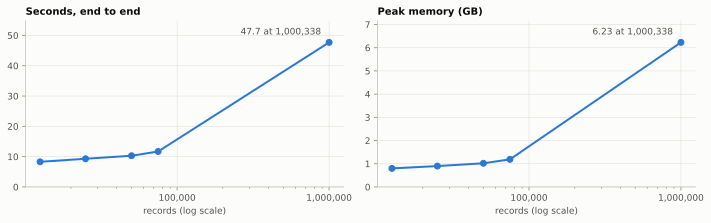

In [14]:
full_steps = pd.DataFrame(run.steps)[["step", "big_o", "filled", "seconds", "peak_memory_gb"]]
inc_steps = pd.DataFrame(inc.steps)[["step", "big_o", "filled", "seconds"]]
display(full_steps, inc_steps)

curve = table_after((S.root / "reports" / "benchmark.md").read_text(encoding="utf-8"), "## Cost")
curve = curve[pd.to_numeric(curve["seconds"], errors="coerce").notna()].astype({"records": int, "seconds": float, "peak_memory_gb": float})
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, col, title in ((a, "seconds", "Seconds, end to end"), (b, "peak_memory_gb", "Peak memory (GB)")):
    ax.plot(curve["records"], curve[col], color=BLUE, marker="o", markersize=6)
    ax.set(title=title, xlabel="records (log scale)", xscale="log", ylim=(0, curve[col].max() * 1.15))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:,.0f}"))
    last = curve.iloc[-1]
    ax.annotate(f"{last[col]:g} at {last['records']:,}", (last["records"], last[col]), textcoords="offset points",
                xytext=(-8, 8), ha="right", color=INK2)
finish(fig)